# DC-PMI first-error detection

Four deterministic examples per task type across MR-GSM8K, BIG-Bench Mistake, and ProcessBench. Qwen3.5-4B is scored with thinking disabled. Scores are cached in `cache/dc_pmi.sqlite`; subsequent runs only score cache misses. ROC curves use correct steps and annotated first-error steps, excluding subsequent steps. This small sample is a demonstration, not a reliable benchmark estimate.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from experiment_setup.benchmarks import load_examples, sample_tasks
from experiment_setup.dc_pmi import evaluate
from experiment_setup.plots import plot_first_error_roc, plot_first_error_trajectories

In [3]:
MODEL_ID = "Qwen/Qwen3.5-4B"
examples = sample_tasks(load_examples(), size=4, seed=42)
assert len(examples) == 48
display(pd.DataFrame(
    [{"benchmark": e.benchmark, "task": e.task, "first_error": e.label is not None}
     for e in examples]
).groupby(["benchmark", "task"]).agg(n_examples=("first_error", "size"),
                                      n_first_errors=("first_error", "sum")))

n_examples  n_first_errors
benchmark         task                                                 
BIG-Bench-Mistake dyck_languages                      4               3
                  logical_deduction                   4               4
                  multistep_arithmetic                4               4
                  tracking_shuffled_objects           4               4
                  word_sorting                        4               4
MR-GSM8K          POT                                 4               1
                  original                            4               3
                  reversed                            4               1
ProcessBench      gsm8k                               4               2
                  math                                4               0
                  olympiadbench                       4               2
                  omnimath                            4               4

## Score the reference reasoning traces

The shared evaluator applies the non-thinking chat template and computes perplexity from average token log-likelihood, and three DC-PMI context ablations from differences of full-step log-likelihood sums.

In [4]:
scores = evaluate(examples, model_id=MODEL_ID, batch_size=1, inference_batch_size=1)
display(scores.head())

2026-10-31 12:22:48 INFO experiment_setup: Starting evaluation: model=Qwen/Qwen3.5-4B examples=48 cache_only=False


Evaluating:   0%|          | 0/48 [00:00<?, ?example/s]

2026-10-31 12:22:49 INFO experiment_setup: Cache lookup complete: 48/48 examples loaded from cache; 0 need inference
2026-10-31 12:22:49 INFO experiment_setup: Evaluation complete: 48 examples (cache hits=48, generated=0)


,benchmark,task,uid,label,step,first_error,verified,cache_key,tokens,average_log_likelihood,perplexity,dc_pmi_generic_domain,dc_pmi_question_ablation,dc_pmi_history_ablation
0,MR-GSM8K,original,c308cb45-c67f-4db1-baa2-7cef10675aa6,NaN,0,False,True,e0a542cca3381c72893e7ed16eb203b2bed8be570bffb2...,16,-1.063850,2.897506,45.431766,45.410578,-0.045314
1,MR-GSM8K,original,c308cb45-c67f-4db1-baa2-7cef10675aa6,NaN,1,False,True,e0a542cca3381c72893e7ed16eb203b2bed8be570bffb2...,33,-0.250636,1.284842,60.908909,17.407037,17.329319
2,MR-GSM8K,original,c308cb45-c67f-4db1-baa2-7cef10675aa6,NaN,2,False,True,e0a542cca3381c72893e7ed16eb203b2bed8be570bffb2...,33,-0.164265,1.178526,68.124658,6.069657,25.352462
3,MR-GSM8K,original,c308cb45-c67f-4db1-baa2-7cef10675aa6,NaN,3,False,True,e0a542cca3381c72893e7ed16eb203b2bed8be570bffb2...,27,-0.461025,1.585699,52.150944,-2.782050,18.733222
4,MR-GSM8K,original,c308cb45-c67f-4db1-baa2-7cef10675aa6,NaN,4,False,True,e0a542cca3381c72893e7ed16eb203b2bed8be570bffb2...,8,-2.058676,7.835585,14.936405,0.850275,18.672198


## ROC curves and AUC by benchmark

Positive class: the annotated first incorrect step. Lower raw DC-PMI scores predict first errors, so ROC/AUC uses their negative values; higher perplexity predicts first errors. Curves pool all steps across task types *within* each benchmark, including steps after the first error (counted as negatives).

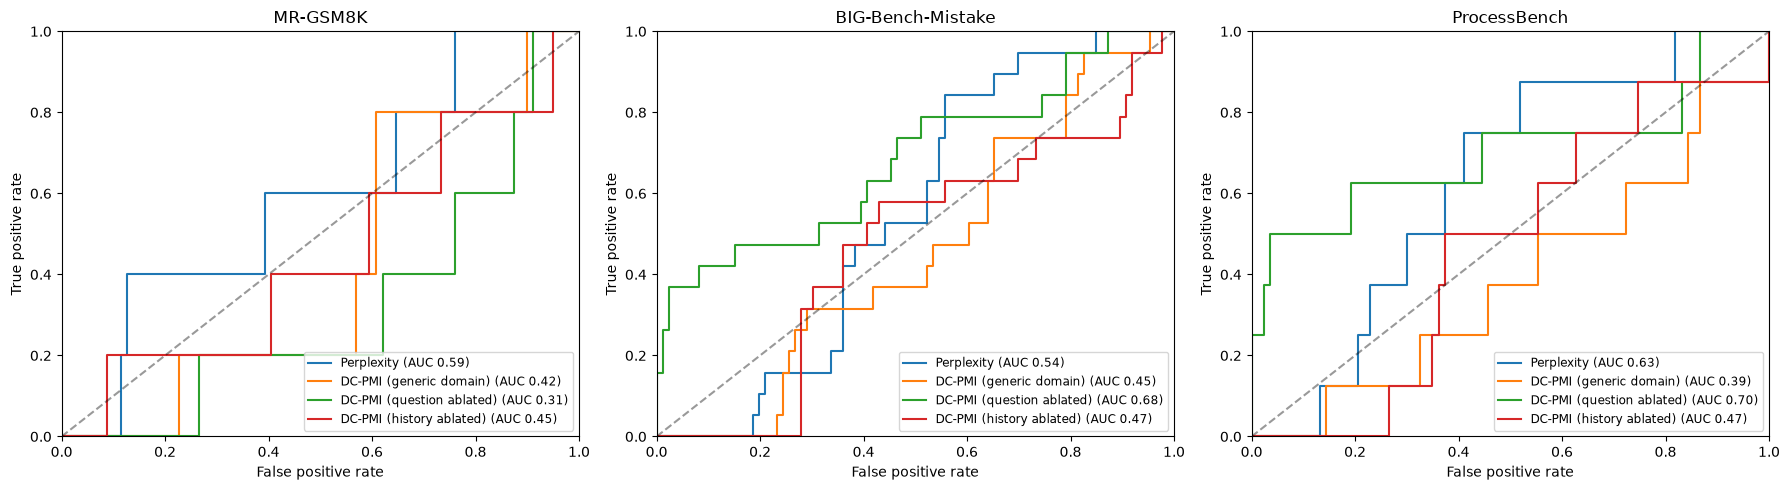

metric,dc_pmi_generic_domain,dc_pmi_history_ablation,dc_pmi_question_ablation,perplexity
benchmark,,,,
BIG-Bench-Mistake,0.454,0.466,0.682,0.545
MR-GSM8K,0.418,0.446,0.314,0.592
ProcessBench,0.386,0.465,0.700,0.627


In [5]:
fig, aucs = plot_first_error_roc(scores)
display(fig)
plt.close(fig)
display(aucs.pivot(index="benchmark", columns="metric", values="auc").round(3))

## Scores around the first error

Each trace is aligned at its first annotated error (step 0). Lines show mean absolute scores pooled across annotated traces from all benchmarks; bands show 95% bootstrap confidence intervals. The dotted horizontal line marks the mean score at the first error, and the y-axis is centered there. Steps after the first error are included.

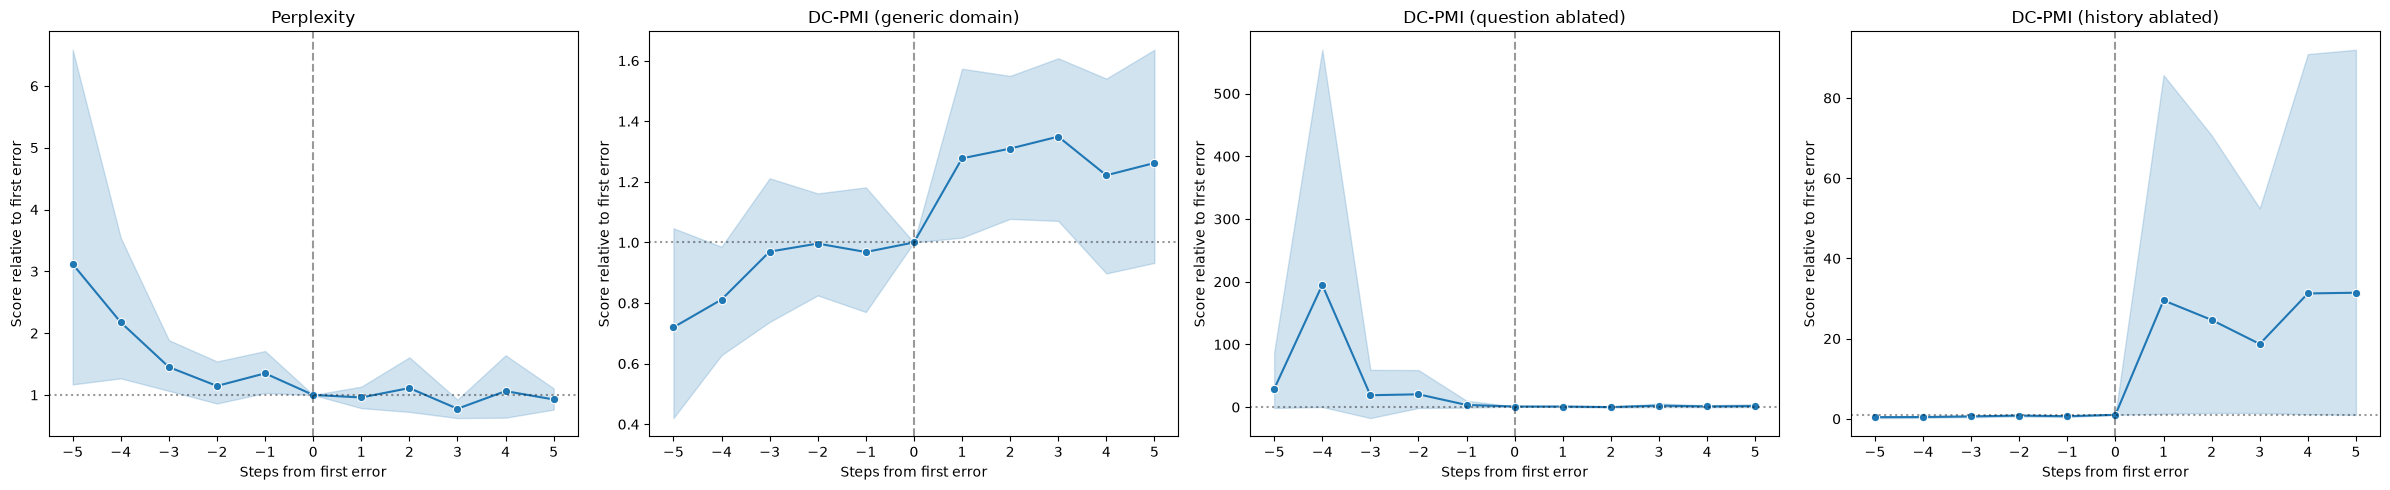

In [6]:
fig = plot_first_error_trajectories(scores)
display(fig)
plt.close(fig)